# Conformal prediction for LLM-based classification

How reliable is a small open-weight LLM used as a zero-shot classifier on biomedical
abstracts, and what do calibration and conformal prediction actually fix?

In [3]:
# %% CELL 0 — install (run once)
!python3 -m pip install -q numpy pandas matplotlib scikit-learn scipy torch transformers datasets
!python3 -m pip install -q mlx-lm            # Apple Silicon only, for the larger model

In [4]:
# %% CELL 1 — shared configuration
from pathlib import Path
import numpy as np

DATASET_ID   = "TimSchopf/medical_abstracts"
TEXT_COL     = "medical_abstract"
LABEL_COL    = "condition_label"
LABEL_NAMES  = {1:"neoplasms", 2:"digestive system diseases", 3:"nervous system diseases",
                4:"cardiovascular diseases", 5:"general pathological conditions"}

N_CALIB, N_TEST = 500, 500
MAX_CHARS       = 2000
ALPHA           = 0.10          # target coverage = 1 - ALPHA
SPLIT_SEED      = 0

# New, empty cache folder: every score is recomputed with the current crc32 seeds.
# The old "cache/" folder is no longer read (it holds scores from the hash()-seeded runs).
# Rule: whenever the seeding or the prompt changes, change this folder name.
CACHE_ROOT = Path("cache_crc32"); CACHE_ROOT.mkdir(parents=True, exist_ok=True)
RESULTS = {}                    # tag -> {"P_calib":..., "P_test":..., "meta":...}

print("target coverage:", 1 - ALPHA)

target coverage: 0.9


In [5]:
# %% CELL 2 — dataset and fixed splits (shared by every model)
import numpy as np, pandas as pd
from datasets import load_dataset

raw = load_dataset(DATASET_ID)
split = "train" if "train" in raw else list(raw.keys())[0]
df = raw[split].to_pandas().rename(columns={TEXT_COL:"text", LABEL_COL:"label"})[["text","label"]].dropna()
df["label"] = df["label"].map(LABEL_NAMES)
assert df["label"].notna().all(), "label mapping incomplete - check the integer codes"
df["text"] = df["text"].astype(str).str.slice(0, MAX_CHARS)

CLASSES      = sorted(df["label"].unique().tolist())
CLASS_TO_IDX = {c:i for i,c in enumerate(CLASSES)}
K            = len(CLASSES)

rng  = np.random.default_rng(SPLIT_SEED)
idx  = rng.permutation(len(df))[: N_CALIB + N_TEST]
work = df.iloc[idx].reset_index(drop=True)
calib_df = work.iloc[:N_CALIB].reset_index(drop=True)
test_df  = work.iloc[N_CALIB:].reset_index(drop=True)

y_calib = np.array([CLASS_TO_IDX[l] for l in calib_df["label"]])
y_test  = np.array([CLASS_TO_IDX[l] for l in test_df["label"]])

print(f"{len(df)} examples | {K} classes | calib={len(calib_df)} test={len(test_df)}")
print(df["label"].value_counts().to_string())

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


11550 examples | 5 classes | calib=500 test=500
label
general pathological conditions    3844
neoplasms                          2530
cardiovascular diseases            2441
nervous system diseases            1540
digestive system diseases          1195


In [6]:
# %% CELL 3 — pure analysis functions (no model, no globals)
import numpy as np, pandas as pd
from scipy.optimize import minimize_scalar

def lac_scores(P, y):
    return 1.0 - P[np.arange(len(y)), y]

def aps_scores(P, y):
    order = np.argsort(-P, axis=1)
    cum   = np.cumsum(np.take_along_axis(P, order, axis=1), axis=1)
    rank  = np.argmax(order == y[:, None], axis=1)
    return cum[np.arange(len(y)), rank]

def conformal_quantile(scores, alpha):
    n = len(scores)
    if n == 0: return 1.0
    q_level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    return float(np.quantile(scores, q_level, method="higher"))

def lac_sets(P, qhat):
    return (1.0 - P) <= qhat

def aps_sets(P, qhat):
    order       = np.argsort(-P, axis=1)
    sorted_p    = np.take_along_axis(P, order, axis=1)
    cum         = np.cumsum(sorted_p, axis=1)
    keep_sorted = cum - sorted_p < qhat
    keep_sorted[:, 0] = True
    sets = np.zeros_like(keep_sorted)
    np.put_along_axis(sets, order, keep_sorted, axis=1)
    return sets

def mondrian_quantiles(P_cal, y_cal, alpha, n_classes):
    s = lac_scores(P_cal, y_cal)
    return np.array([conformal_quantile(s[y_cal == k], alpha) if (y_cal == k).sum() else 1.0
                     for k in range(n_classes)])

def set_report(sets, y, name):
    return {"method": name,
            "coverage":     round(float(sets[np.arange(len(y)), y].mean()), 3),
            "avg_set_size": round(float(sets.sum(1).mean()), 2),
            "empty_sets":   round(float((sets.sum(1) == 0).mean()), 3)}

def softmax_T(Z, T):
    z = Z / T; z = z - z.max(1, keepdims=True); e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def fit_temperature(P_cal, y_cal):
    Z = np.log(np.clip(P_cal, 1e-12, 1.0))
    def nll(T):
        p = softmax_T(Z, T)
        return -np.log(p[np.arange(len(y_cal)), y_cal] + 1e-12).mean()
    return float(minimize_scalar(nll, bounds=(0.05, 50.0), method="bounded").x)

def apply_temperature(P, T):
    return softmax_T(np.log(np.clip(P, 1e-12, 1.0)), T)

def ece(P, y, n_bins=15):
    conf, pred = P.max(1), P.argmax(1)
    acc = (pred == y).astype(float)
    edges, out = np.linspace(0, 1, n_bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum(): out += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(out)

print("analysis helpers ready")

analysis helpers ready


In [7]:
# %% CELL 4 — scorers: each owns its model, nothing shared
import string, numpy as np

LETTERS = list(string.ascii_uppercase)[:K]

def _prompt_text(text, ordered_classes):
    block = "\n".join(f"{L}) {c}" for L, c in zip(LETTERS, ordered_classes))
    return ("Classify the following medical abstract into exactly one category.\n\n"
            f"Abstract:\n{text}\n\n"
            f"Categories:\n{block}\n\n"
            "Answer with the single letter of the correct category.")

class HFScorer:
    """transformers backend (CPU / MPS / CUDA)."""
    backend = "hf"
    def __init__(self, model_id):
        import torch
        from transformers import AutoTokenizer, AutoModelForCausalLM
        self.torch  = torch
        self.model_id = model_id
        self.device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
        dtype = torch.bfloat16 if self.device != "cpu" else torch.float32
        self.tok = AutoTokenizer.from_pretrained(model_id)
        self.model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=dtype).to(self.device)
        self.model.eval()
        self.letter_ids = torch.tensor(
            [self.tok.encode(L, add_special_tokens=False)[0] for L in LETTERS], device=self.device)

    def probs(self, text, seed):
        perm    = np.random.default_rng(seed).permutation(K)
        ordered = [CLASSES[i] for i in perm]
        prompt  = self.tok.apply_chat_template(
            [{"role":"user","content":_prompt_text(text, ordered)}],
            tokenize=False, add_generation_prompt=True)
        enc = self.tok(prompt, return_tensors="pt", add_special_tokens=False).to(self.device)
        with self.torch.no_grad():
            logits = self.model(**enc).logits[0, -1, :]
        sel  = logits[self.letter_ids].float()
        ppos = self.torch.softmax(sel, dim=-1).cpu().numpy().astype(np.float64)
        p = np.zeros(K); p[perm] = ppos
        return p

    def release(self):
        del self.model; import gc; gc.collect()

class MLXScorer:
    """mlx-lm backend (Apple Silicon, 4-bit quantised)."""
    backend = "mlx"
    def __init__(self, model_id):
        import mlx.core as mx
        from mlx_lm import load
        self.mx = mx
        self.model_id = model_id
        self.model, self.tok = load(model_id)
        self.letter_ids = [self.tok.encode(L, add_special_tokens=False)[0] for L in LETTERS]

    def probs(self, text, seed):
        perm    = np.random.default_rng(seed).permutation(K)
        ordered = [CLASSES[i] for i in perm]
        prompt  = self.tok.apply_chat_template(
            [{"role":"user","content":_prompt_text(text, ordered)}],
            tokenize=False, add_generation_prompt=True)
        ids    = self.mx.array([self.tok.encode(prompt)])
        logits = self.model(ids)[0, -1, :]
        sel    = np.array(logits[self.letter_ids], dtype=np.float64)
        e      = np.exp(sel - sel.max()); ppos = e / e.sum()
        p = np.zeros(K); p[perm] = ppos
        return p

    def release(self):
        del self.model; import gc; gc.collect()

print("scorers defined")

scorers defined


In [8]:
# %% CELL 5 — scoring runner with per-model cache
import json, hashlib
import numpy as np
import zlib

def run_scoring(scorer, tag, force=False, verbose_every=50):
    """Score calibration and test sets with `scorer`; results stored under RESULTS[tag]."""
    cache_dir  = CACHE_ROOT / tag; cache_dir.mkdir(parents=True, exist_ok=True)
    cache_path = cache_dir / "scores.json"
    sig = hashlib.md5(
        (scorer.model_id + "|" + scorer.backend + "|" + "|".join(CLASSES) +
         "|randperm|" + _prompt_text("PROBE", CLASSES)).encode()).hexdigest()[:8]

    cache = json.loads(cache_path.read_text()) if (cache_path.exists() and not force) else {}

    def score_frame(frame, split_name):
        out, dirty = np.zeros((len(frame), K)), False
        for i, row in frame.iterrows():
            key = f"{sig}:{split_name}:{i}"
            if key not in cache:
                cache[key] = scorer.probs(row["text"], seed=zlib.crc32(f"{split_name}:{i}".encode()) % (2**32)).tolist()
                dirty = True
                if verbose_every and (i + 1) % verbose_every == 0:
                    cache_path.write_text(json.dumps(cache))
                    print(f"    {split_name} {i+1}/{len(frame)}")
            out[i] = cache[key]
        if dirty: cache_path.write_text(json.dumps(cache))
        return out

    print(f"[{tag}] scoring with {scorer.model_id} ({scorer.backend}), signature {sig}")
    P_calib = score_frame(calib_df, "calib")
    P_test  = score_frame(test_df,  "test")
    acc = float((P_test.argmax(1) == y_test).mean())
    RESULTS[tag] = {"P_calib": P_calib, "P_test": P_test,
                    "meta": {"model_id": scorer.model_id, "backend": scorer.backend, "signature": sig}}
    print(f"[{tag}] done - top-1 accuracy = {acc:.3f}")
    return RESULTS[tag]

print("runner ready")

runner ready


In [9]:
# %% CELL 6 — model A: Qwen2.5-3B (transformers)
TAG_A = "qwen2.5-3b"
scorer_a = HFScorer("Qwen/Qwen2.5-3B-Instruct")

# sanity check before the long run
_p = scorer_a.probs(test_df.loc[0, "text"], seed=0)
print("probs sum:", round(float(_p.sum()), 4),
      "| pred:", CLASSES[int(_p.argmax())], "| true:", test_df.loc[0, "label"])

run_scoring(scorer_a, TAG_A)
scorer_a.release()          # free memory before loading the bigger model

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 434/434 [00:00<00:00, 6189.02it/s]


probs sum: 1.0 | pred: neoplasms | true: neoplasms
[qwen2.5-3b] scoring with Qwen/Qwen2.5-3B-Instruct (hf), signature 0427657d
[qwen2.5-3b] done - top-1 accuracy = 0.638


In [10]:
# %% CELL 7 — model B: Qwen2.5-7B, 4-bit (mlx)
TAG_B = "qwen2.5-7b-4bit"
scorer_b = MLXScorer("mlx-community/Qwen2.5-7B-Instruct-4bit")

_p = scorer_b.probs(test_df.loc[0, "text"], seed=0)
print("probs sum:", round(float(_p.sum()), 4),
      "| pred:", CLASSES[int(_p.argmax())], "| true:", test_df.loc[0, "label"])

run_scoring(scorer_b, TAG_B)
scorer_b.release()

Fetching 9 files: 100%|██████████| 9/9 [00:00<00:00, 2577.41it/s]


probs sum: 1.0 | pred: neoplasms | true: neoplasms
[qwen2.5-7b-4bit] scoring with mlx-community/Qwen2.5-7B-Instruct-4bit (mlx), signature a085566a
    calib 100/500
    calib 150/500
    calib 200/500
    calib 250/500
    calib 300/500
    calib 350/500
    calib 400/500
    calib 450/500
    calib 500/500
    test 50/500
    test 100/500
    test 150/500
    test 200/500
    test 250/500
    test 300/500
    test 350/500
    test 400/500
    test 450/500
    test 500/500
[qwen2.5-7b-4bit] done - top-1 accuracy = 0.638


In [11]:
# %% CELL 8 — full analysis for one model (pure: reads only RESULTS[tag])
import numpy as np, pandas as pd

def analyse(tag, alpha=ALPHA, show=True):
    P_cal, P_tst = RESULTS[tag]["P_calib"], RESULTS[tag]["P_test"]

    acc = float((P_tst.argmax(1) == y_test).mean())
    conf_mean = float(P_tst.max(1).mean())

    # --- conformal on raw probabilities
    q_lac  = conformal_quantile(lac_scores(P_cal, y_calib), alpha)
    q_aps  = conformal_quantile(aps_scores(P_cal, y_calib), alpha)
    q_mond = mondrian_quantiles(P_cal, y_calib, alpha, K)
    S_lac, S_aps = lac_sets(P_tst, q_lac), aps_sets(P_tst, q_aps)
    S_mond = (1.0 - P_tst) <= q_mond[None, :]

    # --- temperature scaling, then conformal again
    T = fit_temperature(P_cal, y_calib)
    P_cal_T, P_tst_T = apply_temperature(P_cal, T), apply_temperature(P_tst, T)
    q_lac_T  = conformal_quantile(lac_scores(P_cal_T, y_calib), alpha)
    q_mond_T = mondrian_quantiles(P_cal_T, y_calib, alpha, K)
    S_lac_T  = lac_sets(P_tst_T, q_lac_T)
    S_mond_T = (1.0 - P_tst_T) <= q_mond_T[None, :]

    sets_tbl = pd.DataFrame([
        set_report(S_lac,    y_test, "LAC"),
        set_report(S_aps,    y_test, "APS"),
        set_report(S_mond,   y_test, "LAC class-conditional"),
        set_report(S_lac_T,  y_test, "LAC + temperature"),
        set_report(S_mond_T, y_test, "LAC class-cond. + temperature"),
    ])

    per_class = pd.DataFrame([{
        "class": c, "n": int((y_test == k).sum()),
        "cov_marginal":  round(float(S_lac[y_test == k, k].mean()), 3),
        "cov_classwise": round(float(S_mond[y_test == k, k].mean()), 3),
    } for k, c in enumerate(CLASSES) if (y_test == k).sum()])

    sing = S_lac_T.sum(1) == 1
    wrong = P_tst_T.argmax(1) != y_test
    summary = {
        "model": tag, "accuracy": round(acc, 3),
        "mean_confidence": round(conf_mean, 3),
        "overconfidence_gap": round(conf_mean - acc, 3),
        "T": round(T, 2),
        "ECE_raw": round(ece(P_tst, y_test), 3),
        "ECE_scaled": round(ece(P_tst_T, y_test), 3),
        "acc_after_T": round(float((P_tst_T.argmax(1) == y_test).mean()), 3),
        "size_LAC": round(float(S_lac.sum(1).mean()), 2),
        "size_mondrian": round(float(S_mond.sum(1).mean()), 2),
        "singletons": round(float(sing.mean()), 3),
        "singletons_wrong": round(float(wrong[sing].mean()), 3) if sing.sum() else None,
    }

    RESULTS[tag]["analysis"] = {"summary": summary, "sets": sets_tbl,
                                "per_class": per_class, "T": T,
                                "P_test_T": P_tst_T, "S_lac": S_lac, "S_lac_T": S_lac_T}

    if show:
        print(f"===== {tag} =====")
        print(f"accuracy {acc:.3f} | mean confidence {conf_mean:.3f} "
              f"| overconfidence gap {conf_mean-acc:.3f}")
        print(f"temperature T = {T:.2f} | ECE {ece(P_tst, y_test):.3f} -> {ece(P_tst_T, y_test):.3f} "
              f"| accuracy after scaling {summary['acc_after_T']:.3f}")
        print(f"qhat LAC {q_lac:.6f} -> after temperature {q_lac_T:.4f}")
        print()
        print(sets_tbl.to_string(index=False))
        print()
        print(per_class.to_string(index=False))
        if sing.sum():
            print(f"\nsingletons: {sing.mean():.1%} of test, of which wrong: {wrong[sing].mean():.1%}")
        for thr in (0.7, 0.8, 0.9):
            m = P_tst_T.max(1) >= thr
            if m.sum():
                print(f"  confidence >= {thr}: n={int(m.sum()):3d}  errors={1-(P_tst_T.argmax(1)==y_test)[m].mean():.1%}")
    return summary

for tag in RESULTS:
    analyse(tag); print()

===== qwen2.5-3b =====
accuracy 0.638 | mean confidence 0.987 | overconfidence gap 0.349
temperature T = 7.41 | ECE 0.353 -> 0.052 | accuracy after scaling 0.638
qhat LAC 1.000000 -> after temperature 0.9321

                       method  coverage  avg_set_size  empty_sets
                          LAC     0.894          3.24         0.0
                          APS     0.928          3.89         0.0
        LAC class-conditional     0.910          2.48         0.0
            LAC + temperature     0.908          3.38         0.0
LAC class-cond. + temperature     0.920          2.61         0.0

                          class   n  cov_marginal  cov_classwise
        cardiovascular diseases 116         0.966          0.905
      digestive system diseases  51         0.980          0.941
general pathological conditions 165         0.770          0.909
                      neoplasms  97         0.928          0.897
        nervous system diseases  71         0.958          0.915

sin

In [12]:
# %% CELL 9 — comparison across models
import pandas as pd
comparison = pd.DataFrame([RESULTS[t]["analysis"]["summary"] for t in RESULTS])
print(comparison.to_string(index=False))
comparison.to_csv("model_comparison.csv", index=False)

          model  accuracy  mean_confidence  overconfidence_gap    T  ECE_raw  ECE_scaled  acc_after_T  size_LAC  size_mondrian  singletons  singletons_wrong
     qwen2.5-3b     0.638            0.987               0.349 7.41    0.353       0.052        0.638      3.24           2.48       0.016             0.125
qwen2.5-7b-4bit     0.638            0.987               0.349 9.96    0.350       0.080        0.638      2.79           2.54       0.140             0.243


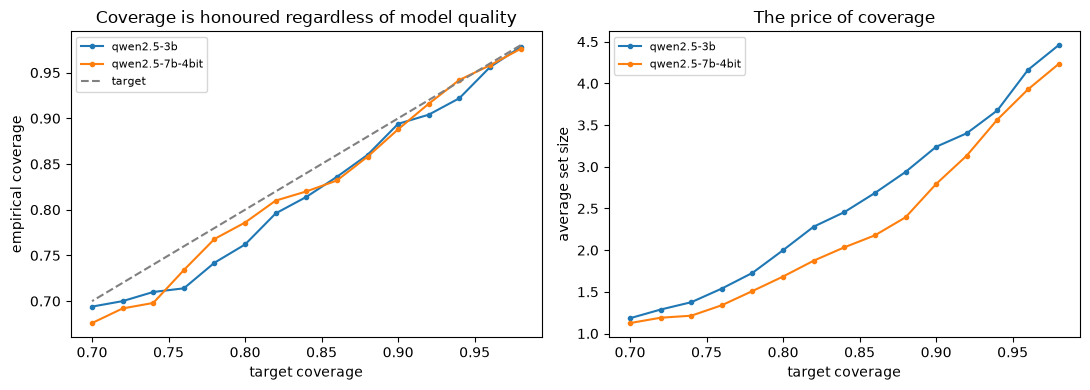

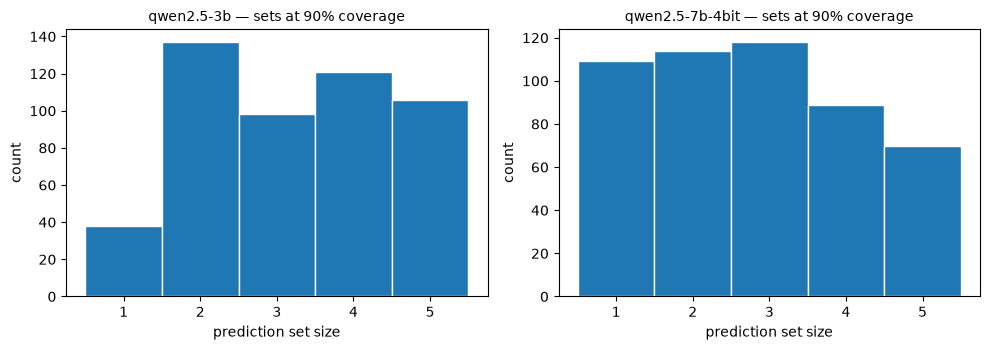

In [13]:
# %% CELL 10 — figures
import numpy as np, matplotlib.pyplot as plt

alphas = np.arange(0.02, 0.31, 0.02)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for tag in RESULTS:
    P_cal, P_tst = RESULTS[tag]["P_calib"], RESULTS[tag]["P_test"]
    s_cal = lac_scores(P_cal, y_calib)
    cov, size = [], []
    for a in alphas:
        S = lac_sets(P_tst, conformal_quantile(s_cal, a))
        cov.append(S[np.arange(len(y_test)), y_test].mean())
        size.append(S.sum(1).mean())
    ax[0].plot(1 - alphas, cov, marker="o", ms=3, label=tag)
    ax[1].plot(1 - alphas, size, marker="o", ms=3, label=tag)
ax[0].plot(1 - alphas, 1 - alphas, ls="--", c="gray", label="target")
ax[0].set_xlabel("target coverage"); ax[0].set_ylabel("empirical coverage")
ax[0].set_title("Coverage is honoured regardless of model quality"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("target coverage"); ax[1].set_ylabel("average set size")
ax[1].set_title("The price of coverage"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("coverage_vs_alpha.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, len(RESULTS), figsize=(5*len(RESULTS), 3.6), squeeze=False)
for j, tag in enumerate(RESULTS):
    S = RESULTS[tag]["analysis"]["S_lac"]
    a = axes[0][j]
    a.hist(S.sum(1), bins=np.arange(0.5, K + 1.5), edgecolor="white")
    a.set_xticks(range(1, K + 1))
    a.set_xlabel("prediction set size"); a.set_ylabel("count")
    a.set_title(f"{tag} — sets at {1-ALPHA:.0%} coverage", fontsize=10)
plt.tight_layout(); plt.savefig("set_sizes.png", dpi=150); plt.show()

## Prompt test

prompt variants: ['letters', 'numbers', 'letters_role'] | orderings: ['fixed', 'reversed', 'random']


Loading weights: 100%|██████████| 434/434 [00:00<00:00, 6015.56it/s]


letters        marker mass = 1.000
numbers        marker mass = 1.000
letters_role   marker mass = 1.000
[letters|fixed] scoring (signature 2e2fa53b)
    calib 100/500
    calib 200/500
    calib 300/500
    calib 400/500
    calib 500/500
    test 100/500
    test 200/500
    test 300/500
    test 400/500
    test 500/500
[letters|fixed] accuracy = 0.642
[letters|reversed] scoring (signature a125a10c)
    calib 100/500
    calib 200/500
    calib 300/500
    calib 400/500
    calib 500/500
    test 100/500
    test 200/500
    test 300/500
    test 400/500
    test 500/500
[letters|reversed] accuracy = 0.636
[letters|random] scoring (signature b956b288)
    calib 100/500
    calib 200/500
    calib 300/500
    calib 400/500
    calib 500/500
    test 100/500
    test 200/500
    test 300/500
    test 400/500
    test 500/500
[letters|random] accuracy = 0.638
[numbers|fixed] scoring (signature 09d203fe)
    calib 100/500
    calib 200/500
    calib 300/500
    calib 400/500
    calib 5

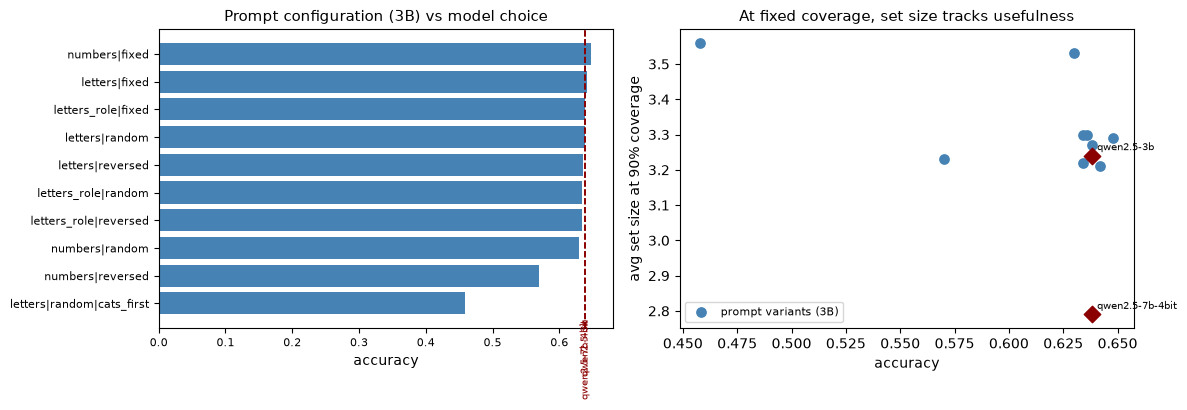

In [14]:
# %% CELL 12 — prompt variants: parametrised prompt builder
# Append after CELL 11 in Conformal_LLM_clean.ipynb.
# Everything here is fixed-model: only the prompt changes.

import string, numpy as np

LETTERS = list(string.ascii_uppercase)[:K]
DIGITS  = [str(i + 1) for i in range(K)]

PROMPT_STYLES = {
    # marker set, role preamble, answer-word
    "letters":      (LETTERS, False, "letter"),
    "numbers":      (DIGITS,  False, "number"),
    "letters_role": (LETTERS, True,  "letter"),
}
ORDERINGS = ["fixed", "reversed", "random"]

def make_prompt(text, ordered_classes, style="letters", abstract_first=True):
    marks, use_role, answer_word = PROMPT_STYLES[style]
    block = "\n".join(f"{m}) {c}" for m, c in zip(marks, ordered_classes))
    head  = "You are a medical expert. " if use_role else ""
    if abstract_first:
        body = (f"{head}Classify the following medical abstract into exactly one category.\n\n"
                f"Abstract:\n{text}\n\nCategories:\n{block}\n\n")
    else:
        body = (f"{head}Classify a medical abstract into exactly one of these categories.\n\n"
                f"Categories:\n{block}\n\nAbstract:\n{text}\n\n")
    return body + f"Answer with the single {answer_word} of the correct category."

def class_order(seed, ordering):
    """Return the permutation applied to CLASSES for this example."""
    if ordering == "fixed":
        return np.arange(K)
    if ordering == "reversed":
        return np.arange(K)[::-1].copy()
    return np.random.default_rng(seed).permutation(K)

print("prompt variants:", list(PROMPT_STYLES), "| orderings:", ORDERINGS)


# %% CELL 13 — scorer that accepts a prompt configuration
import numpy as np

class ConfigurableHFScorer:
    """Same model as HFScorer, but the prompt configuration is an argument."""
    backend = "hf"

    def __init__(self, model_id):
        import torch
        from transformers import AutoTokenizer, AutoModelForCausalLM
        self.torch = torch
        self.model_id = model_id
        self.device = ("mps" if torch.backends.mps.is_available()
                       else "cuda" if torch.cuda.is_available() else "cpu")
        dtype = torch.bfloat16 if self.device != "cpu" else torch.float32
        self.tok = AutoTokenizer.from_pretrained(model_id)
        self.model = AutoModelForCausalLM.from_pretrained(model_id, dtype=dtype).to(self.device)
        self.model.eval()
        self._mark_ids = {}
        for style, (marks, _, _) in PROMPT_STYLES.items():
            self._mark_ids[style] = torch.tensor(
                [self.tok.encode(m, add_special_tokens=False)[0] for m in marks],
                device=self.device)

    def probs(self, text, seed, style="letters", ordering="random", abstract_first=True):
        perm    = class_order(seed, ordering)
        ordered = [CLASSES[i] for i in perm]
        prompt  = self.tok.apply_chat_template(
            [{"role": "user", "content": make_prompt(text, ordered, style, abstract_first)}],
            tokenize=False, add_generation_prompt=True)
        enc = self.tok(prompt, return_tensors="pt", add_special_tokens=False).to(self.device)
        with self.torch.no_grad():
            logits = self.model(**enc).logits[0, -1, :]
        sel  = logits[self._mark_ids[style]].float()
        ppos = self.torch.softmax(sel, dim=-1).cpu().numpy().astype(np.float64)
        p = np.zeros(K); p[perm] = ppos     # positions -> canonical class order
        return p

    def mark_mass(self, text, style="letters"):
        """Diagnostic: how much probability mass sits on the marker tokens."""
        prompt = self.tok.apply_chat_template(
            [{"role": "user", "content": make_prompt(text, CLASSES, style)}],
            tokenize=False, add_generation_prompt=True)
        enc = self.tok(prompt, return_tensors="pt", add_special_tokens=False).to(self.device)
        with self.torch.no_grad():
            logits = self.model(**enc).logits[0, -1, :]
        return float(self.torch.softmax(logits, -1)[self._mark_ids[style]].sum())

scorer_prompt = ConfigurableHFScorer("Qwen/Qwen2.5-3B-Instruct")

for style in PROMPT_STYLES:
    print(f"{style:14s} marker mass = {scorer_prompt.mark_mass(test_df.loc[0,'text'], style):.3f}")


# %% CELL 14 — run the ablation (fixed model, varying prompt)
import json, hashlib
import numpy as np
from pathlib import Path

ABLATION = {}          # config_name -> {"P_calib":..., "P_test":...}

def run_prompt_config(scorer, style, ordering, abstract_first=True, verbose_every=100):
    name = f"{style}|{ordering}" + ("" if abstract_first else "|cats_first")
    cache_dir  = CACHE_ROOT / "ablation"; cache_dir.mkdir(parents=True, exist_ok=True)
    cache_path = cache_dir / "scores.json"
    sig = hashlib.md5((scorer.model_id + "|" + name + "|" + "|".join(CLASSES) + "|" +
                       make_prompt("PROBE", CLASSES, style, abstract_first)).encode()).hexdigest()[:8]
    cache = json.loads(cache_path.read_text()) if cache_path.exists() else {}

    def score_frame(frame, split_name):
        out, dirty = np.zeros((len(frame), K)), False
        for i, row in frame.iterrows():
            key = f"{sig}:{split_name}:{i}"
            if key not in cache:
                cache[key] = scorer.probs(
                    row["text"], seed=zlib.crc32(f"{split_name}:{i}".encode()) % (2**32),
                    style=style, ordering=ordering, abstract_first=abstract_first).tolist()
                dirty = True
                if verbose_every and (i + 1) % verbose_every == 0:
                    cache_path.write_text(json.dumps(cache)); print(f"    {split_name} {i+1}/{len(frame)}")
            out[i] = cache[key]
        if dirty: cache_path.write_text(json.dumps(cache))
        return out

    print(f"[{name}] scoring (signature {sig})")
    P_cal, P_tst = score_frame(calib_df, "calib"), score_frame(test_df, "test")
    ABLATION[name] = {"P_calib": P_cal, "P_test": P_tst,
                      "style": style, "ordering": ordering, "abstract_first": abstract_first}
    print(f"[{name}] accuracy = {(P_tst.argmax(1) == y_test).mean():.3f}")
    return ABLATION[name]

for style in ["letters", "numbers", "letters_role"]:
    for ordering in ORDERINGS:
        run_prompt_config(scorer_prompt, style, ordering)

# structural variant: categories before the abstract
run_prompt_config(scorer_prompt, "letters", "random", abstract_first=False)

print(f"\n{len(ABLATION)} configurations scored")


# %% CELL 15 — ablation table: accuracy, calibration, set size
import numpy as np, pandas as pd

rows = []
for name, d in ABLATION.items():
    P_cal, P_tst = d["P_calib"], d["P_test"]
    acc  = float((P_tst.argmax(1) == y_test).mean())
    T    = fit_temperature(P_cal, y_calib)
    P_tT = apply_temperature(P_tst, T)

    q_lac  = conformal_quantile(lac_scores(P_cal, y_calib), ALPHA)
    S_lac  = lac_sets(P_tst, q_lac)
    q_mond = mondrian_quantiles(P_cal, y_calib, ALPHA, K)
    S_mond = (1.0 - P_tst) <= q_mond[None, :]

    # how skewed are the predictions towards a single class?
    share = np.bincount(P_tst.argmax(1), minlength=K) / len(y_test)

    rows.append({
        "config": name,
        "style": d["style"], "ordering": d["ordering"],
        "accuracy": round(acc, 3),
        "mean_conf": round(float(P_tst.max(1).mean()), 3),
        "T": round(T, 2),
        "ECE_raw": round(ece(P_tst, y_test), 3),
        "ECE_scaled": round(ece(P_tT, y_test), 3),
        "coverage_LAC": round(float(S_lac[np.arange(len(y_test)), y_test].mean()), 3),
        "size_LAC": round(float(S_lac.sum(1).mean()), 2),
        "size_mondrian": round(float(S_mond.sum(1).mean()), 2),
        "max_class_share": round(float(share.max()), 3),
    })

ablation_tbl = pd.DataFrame(rows).sort_values("accuracy", ascending=False)
print(ablation_tbl.to_string(index=False))
ablation_tbl.to_csv("prompt_ablation.csv", index=False)


# %% CELL 16 — the headline: prompt variance vs model-scaling effect
import numpy as np, pandas as pd

acc_prompt = ablation_tbl["accuracy"].to_numpy()
size_prompt = ablation_tbl["size_LAC"].to_numpy()

model_accs = {t: RESULTS[t]["analysis"]["summary"]["accuracy"] for t in RESULTS}
model_sizes = {t: RESULTS[t]["analysis"]["summary"]["size_LAC"] for t in RESULTS}

model_gain = max(model_accs.values()) - min(model_accs.values())
prompt_spread = acc_prompt.max() - acc_prompt.min()

print("PROMPT (fixed model, Qwen2.5-3B)")
print(f"  accuracy      : min {acc_prompt.min():.3f}  max {acc_prompt.max():.3f}  "
      f"spread {prompt_spread:.3f}  sd {acc_prompt.std():.3f}")
print(f"  set size @90% : min {size_prompt.min():.2f}  max {size_prompt.max():.2f}")
print()
print("MODEL (best prompt, 3B vs 7B)")
for t, a in model_accs.items():
    print(f"  {t:18s} accuracy {a:.3f}  set size {model_sizes[t]:.2f}")
print(f"  scaling gain  : {model_gain:.3f}")
print()
if model_gain == 0:
    print(f"=> model size changes accuracy by 0.000, prompt formatting spans {prompt_spread:.3f}")
else:
    print(f"=> prompt formatting moves accuracy {prompt_spread / model_gain:.1f}x more than doubling model size")


# %% CELL 17 — figure: prompt sensitivity
import numpy as np, matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

order = ablation_tbl.sort_values("accuracy")
ax[0].barh(order["config"], order["accuracy"], color="steelblue")
for t, a in model_accs.items():
    ax[0].axvline(a, ls="--", lw=1.2, color="darkred")
    ax[0].text(a, -0.6, t, rotation=90, fontsize=7, color="darkred", va="top", ha="center")
ax[0].set_xlabel("accuracy"); ax[0].set_title("Prompt configuration (3B) vs model choice", fontsize=11)
ax[0].tick_params(labelsize=8)

ax[1].scatter(ablation_tbl["accuracy"], ablation_tbl["size_LAC"], s=45, color="steelblue", label="prompt variants (3B)")
for t in RESULTS:
    ax[1].scatter(model_accs[t], model_sizes[t], s=70, marker="D", color="darkred")
    ax[1].annotate(t, (model_accs[t], model_sizes[t]), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax[1].set_xlabel("accuracy"); ax[1].set_ylabel(f"avg set size at {1-ALPHA:.0%} coverage")
ax[1].set_title("At fixed coverage, set size tracks usefulness", fontsize=11)
ax[1].legend(fontsize=8)

plt.tight_layout(); plt.savefig("prompt_ablation.png", dpi=150); plt.show()

## Replicates: three independent draws

Everything above rests on one draw of 500 calibration and 500 test abstracts. Here the same
pipeline is repeated on three disjoint draws from the dataset. Replicate 0 is the original
draw, read back from the cache; replicates 1 and 2 are the next two blocks of the same
permutation, so the three never share an abstract.

In [15]:
# %% CELL 18 — three disjoint replicates of 500 + 500 abstracts, scored with both models
# Replicate 0 reuses the original abstracts, cache keys and option-order seeds: nothing is re-scored.
# Note: changing SPLIT_SEED in CELL 1 is NOT a valid way to get new draws, because the cache in
# CELL 5 is keyed by position in the split, not by abstract: it would return old scores for new abstracts.
import json, hashlib, zlib, gc
import numpy as np

TAG_A, TAG_B = "qwen2.5-3b", "qwen2.5-7b-4bit"
N_REPS   = 3
REP_SIZE = N_CALIB + N_TEST
perm_all = np.random.default_rng(SPLIT_SEED).permutation(len(df))   # same permutation as CELL 2
assert N_REPS * REP_SIZE <= len(df)

def replicate_frames(rep):
    block = df.iloc[perm_all[rep * REP_SIZE:(rep + 1) * REP_SIZE]].reset_index(drop=True)
    cal = block.iloc[:N_CALIB].reset_index(drop=True)
    tst = block.iloc[N_CALIB:].reset_index(drop=True)
    y_c = np.array([CLASS_TO_IDX[l] for l in cal["label"]])
    y_t = np.array([CLASS_TO_IDX[l] for l in tst["label"]])
    return cal, tst, y_c, y_t

_c0, _t0, _, _ = replicate_frames(0)
assert _c0["text"].equals(calib_df["text"]) and _t0["text"].equals(test_df["text"]), \
    "replicate 0 differs from the original split: the cache would be misused"

def scorer_signature(scorer):
    """Identical to the signature computed in CELL 5, so replicate 0 hits the existing cache."""
    return hashlib.md5((scorer.model_id + "|" + scorer.backend + "|" + "|".join(CLASSES) +
                        "|randperm|" + _prompt_text("PROBE", CLASSES)).encode()).hexdigest()[:8]

def score_replicate(scorer, tag, rep, verbose_every=100):
    cache_path = CACHE_ROOT / tag / "scores.json"
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    cache = json.loads(cache_path.read_text()) if cache_path.exists() else {}
    sig   = scorer_signature(scorer)
    prefix = "" if rep == 0 else f"r{rep}:"          # rep 0 keeps the original keys and seeds
    cal, tst, y_c, y_t = replicate_frames(rep)

    def score_frame(frame, split_name):
        out, dirty = np.zeros((len(frame), K)), False
        for i, text in enumerate(frame["text"]):
            ident = f"{prefix}{split_name}:{i}"
            key   = f"{sig}:{ident}"
            if key not in cache:
                cache[key] = scorer.probs(text, seed=zlib.crc32(ident.encode()) % (2**32)).tolist()
                dirty = True
                if verbose_every and (i + 1) % verbose_every == 0:
                    cache_path.write_text(json.dumps(cache))
                    print(f"    rep {rep} {split_name} {i+1}/{len(frame)}")
            out[i] = cache[key]
        if dirty: cache_path.write_text(json.dumps(cache))
        return out

    return {"P_calib": score_frame(cal, "calib"), "P_test": score_frame(tst, "test"),
            "y_calib": y_c, "y_test": y_t}

if "scorer_prompt" in globals():                    # free the ablation model first
    del scorer_prompt; gc.collect()

MODELS = [(TAG_A, lambda: HFScorer("Qwen/Qwen2.5-3B-Instruct")),
          (TAG_B, lambda: MLXScorer("mlx-community/Qwen2.5-7B-Instruct-4bit"))]

REPS = {}                                           # (tag, rep) -> P_calib, P_test, y_calib, y_test
for tag, make_scorer in MODELS:
    scorer = make_scorer()
    for rep in range(N_REPS):
        d = REPS[(tag, rep)] = score_replicate(scorer, tag, rep)
        print(f"[{tag}] replicate {rep}: accuracy {(d['P_test'].argmax(1) == d['y_test']).mean():.3f}")
    scorer.release(); del scorer; gc.collect()

for tag in (TAG_A, TAG_B):                          # replicate 0 must be the main experiment
    if tag in RESULTS:
        assert np.array_equal(REPS[(tag, 0)]["P_test"], RESULTS[tag]["P_test"])
print("replicate 0 identical to the main results")

Loading weights: 100%|██████████| 434/434 [00:00<00:00, 6193.99it/s]


[qwen2.5-3b] replicate 0: accuracy 0.638
    rep 1 calib 100/500
    rep 1 calib 200/500
    rep 1 calib 300/500
    rep 1 calib 400/500
    rep 1 calib 500/500
    rep 1 test 100/500
    rep 1 test 200/500
    rep 1 test 300/500
    rep 1 test 400/500
    rep 1 test 500/500
[qwen2.5-3b] replicate 1: accuracy 0.586
    rep 2 calib 100/500
    rep 2 calib 200/500
    rep 2 calib 300/500
    rep 2 calib 400/500
    rep 2 calib 500/500
    rep 2 test 100/500
    rep 2 test 200/500
    rep 2 test 300/500
    rep 2 test 400/500
    rep 2 test 500/500
[qwen2.5-3b] replicate 2: accuracy 0.618


Fetching 9 files: 100%|██████████| 9/9 [00:00<00:00, 1802.19it/s]


[qwen2.5-7b-4bit] replicate 0: accuracy 0.638
    rep 1 calib 100/500
    rep 1 calib 200/500
    rep 1 calib 300/500
    rep 1 calib 400/500
    rep 1 calib 500/500
    rep 1 test 100/500
    rep 1 test 200/500
    rep 1 test 300/500
    rep 1 test 400/500
    rep 1 test 500/500
[qwen2.5-7b-4bit] replicate 1: accuracy 0.598
    rep 2 calib 100/500
    rep 2 calib 200/500
    rep 2 calib 300/500
    rep 2 calib 400/500
    rep 2 calib 500/500
    rep 2 test 100/500
    rep 2 test 200/500
    rep 2 test 300/500
    rep 2 test 400/500
    rep 2 test 500/500
[qwen2.5-7b-4bit] replicate 2: accuracy 0.650
replicate 0 identical to the main results


In [16]:
# %% CELL 19 — every metric on each replicate, then mean and spread over the three
import numpy as np, pandas as pd

TAG_A, TAG_B = "qwen2.5-3b", "qwen2.5-7b-4bit"
GPC = CLASS_TO_IDX["general pathological conditions"]

def coverage(S, y, mask=None):
    idx = np.arange(len(y)) if mask is None else np.flatnonzero(mask)
    return float(S[idx, y[idx]].mean())

def replicate_metrics(P_cal, y_cal, P_tst, y_tst, alpha=ALPHA):
    acc, conf = float((P_tst.argmax(1) == y_tst).mean()), float(P_tst.max(1).mean())
    T = fit_temperature(P_cal, y_cal)
    P_cal_T, P_tst_T = apply_temperature(P_cal, T), apply_temperature(P_tst, T)
    S_lac   = lac_sets(P_tst, conformal_quantile(lac_scores(P_cal, y_cal), alpha))
    S_mond  = (1.0 - P_tst) <= mondrian_quantiles(P_cal, y_cal, alpha, K)[None, :]
    S_lac_T = lac_sets(P_tst_T, conformal_quantile(lac_scores(P_cal_T, y_cal), alpha))
    per_class = [coverage(S_lac, y_tst, y_tst == k) for k in range(K) if (y_tst == k).any()]
    sing  = S_lac_T.sum(1) == 1
    wrong = P_tst_T.argmax(1) != y_tst
    return {
        "accuracy": acc, "mean_confidence": conf, "overconfidence_gap": conf - acc,
        "T": T, "ECE_raw": ece(P_tst, y_tst), "ECE_scaled": ece(P_tst_T, y_tst),
        "coverage_LAC": coverage(S_lac, y_tst),
        "size_LAC": float(S_lac.sum(1).mean()), "size_mondrian": float(S_mond.sum(1).mean()),
        "GPC_cov_marginal": coverage(S_lac, y_tst, y_tst == GPC),
        "GPC_cov_classwise": coverage(S_mond, y_tst, y_tst == GPC),
        "worst_class_cov_marginal": min(per_class),
        "singletons": float(sing.mean()),
        "singletons_wrong": float(wrong[sing].mean()) if sing.any() else np.nan,
    }

per_rep = pd.DataFrame([{"model": tag, "rep": rep,
                         **replicate_metrics(d["P_calib"], d["y_calib"], d["P_test"], d["y_test"])}
                        for (tag, rep), d in REPS.items()])

METRICS = [c for c in per_rep.columns if c not in ("model", "rep")]
long = per_rep.melt(id_vars=["model", "rep"], var_name="metric")
long["metric"] = pd.Categorical(long["metric"], categories=METRICS, ordered=True)
wide = long.pivot_table(index=["model", "metric"], columns="rep", values="value", observed=True)
rep_cols = list(wide.columns)
wide.columns = [f"rep{c}" for c in rep_cols]
wide["mean"] = wide.mean(axis=1)
wide["sd"]   = wide[[f"rep{c}" for c in rep_cols]].std(axis=1, ddof=1)
print(wide.round(3).to_string())
wide.round(4).to_csv("replicates.csv")

acc = per_rep.pivot(index="rep", columns="model", values="accuracy")
print("\naccuracy 7B - 3B per replicate:", (acc[TAG_B] - acc[TAG_A]).round(3).tolist())
print("(sd over 3 replicates is a rough estimate: read the three values, not only the sd)")

                                           rep0    rep1    rep2    mean     sd
model           metric                                                        
qwen2.5-3b      accuracy                  0.638   0.586   0.618   0.614  0.026
                mean_confidence           0.987   0.982   0.984   0.984  0.002
                overconfidence_gap        0.349   0.396   0.366   0.370  0.024
                T                         7.415   7.868   8.115   7.800  0.355
                ECE_raw                   0.353   0.396   0.371   0.373  0.022
                ECE_scaled                0.052   0.050   0.045   0.049  0.003
                coverage_LAC              0.894   0.898   0.908   0.900  0.007
                size_LAC                  3.240   3.586   3.588   3.471  0.200
                size_mondrian             2.480   2.540   2.950   2.657  0.256
                GPC_cov_marginal          0.770   0.786   0.806   0.787  0.018
                GPC_cov_classwise         0.909   0.

          model            metric  mean   p05   p95
     qwen2.5-3b      coverage_LAC 0.902 0.868 0.932
     qwen2.5-3b  GPC_cov_marginal 0.779 0.705 0.846
     qwen2.5-3b GPC_cov_classwise 0.906 0.853 0.954
     qwen2.5-3b          size_LAC 3.478 3.186 3.744
     qwen2.5-3b     size_mondrian 2.737 2.426 3.092
qwen2.5-7b-4bit      coverage_LAC 0.902 0.870 0.932
qwen2.5-7b-4bit  GPC_cov_marginal 0.799 0.737 0.859
qwen2.5-7b-4bit GPC_cov_classwise 0.909 0.853 0.959
qwen2.5-7b-4bit          size_LAC 2.936 2.602 3.260
qwen2.5-7b-4bit     size_mondrian 2.614 2.304 2.926
qwen2.5-3b: GPC covered below 0.85 in 96% of splits (single threshold) vs 4% (class-conditional)
qwen2.5-7b-4bit: GPC covered below 0.85 in 90% of splits (single threshold) vs 3% (class-conditional)


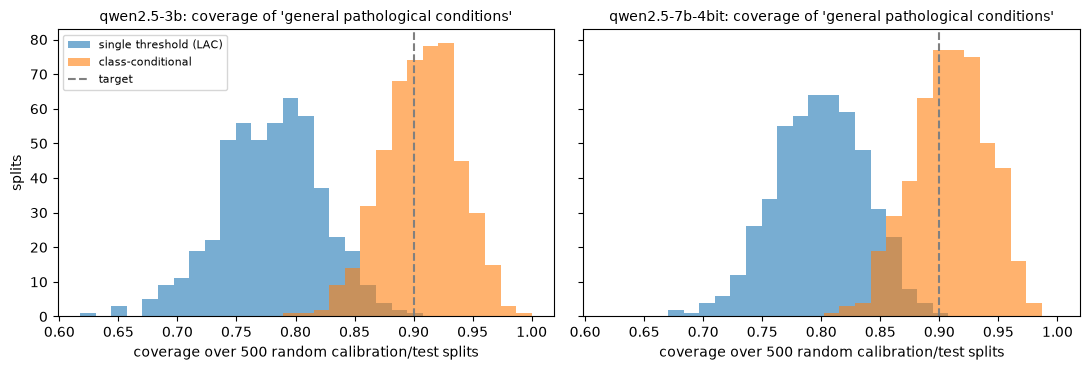

In [17]:
# %% CELL 20 — how much does coverage move with the calibration draw? (no model call, seconds)
# Pool the 3 x 1,000 scored abstracts per model and redraw 500 calibration / 500 test at random,
# B times, with the same raw-probability conformal procedure as CELL 8.
import numpy as np, pandas as pd, matplotlib.pyplot as plt

TAG_A, TAG_B = "qwen2.5-3b", "qwen2.5-7b-4bit"
B, RESPLIT_SEED = 500, 1

rows = []
for tag in (TAG_A, TAG_B):
    P = np.vstack([np.vstack([REPS[(tag, r)]["P_calib"], REPS[(tag, r)]["P_test"]]) for r in range(N_REPS)])
    y = np.concatenate([np.concatenate([REPS[(tag, r)]["y_calib"], REPS[(tag, r)]["y_test"]]) for r in range(N_REPS)])
    rng = np.random.default_rng(RESPLIT_SEED)
    for b in range(B):
        p = rng.permutation(len(y))
        c, t = p[:N_CALIB], p[N_CALIB:N_CALIB + N_TEST]
        S_lac  = lac_sets(P[t], conformal_quantile(lac_scores(P[c], y[c]), ALPHA))
        S_mond = (1.0 - P[t]) <= mondrian_quantiles(P[c], y[c], ALPHA, K)[None, :]
        yt = y[t]
        rows.append({"model": tag, "b": b,
                     "coverage_LAC": coverage(S_lac, yt),
                     "GPC_cov_marginal": coverage(S_lac, yt, yt == GPC),
                     "GPC_cov_classwise": coverage(S_mond, yt, yt == GPC),
                     "size_LAC": float(S_lac.sum(1).mean()),
                     "size_mondrian": float(S_mond.sum(1).mean())})
resplits = pd.DataFrame(rows)

COLS = ["coverage_LAC", "GPC_cov_marginal", "GPC_cov_classwise", "size_LAC", "size_mondrian"]
stats = pd.DataFrame([{"model": tag, "metric": m, "mean": r[m].mean(),
                       "p05": r[m].quantile(0.05), "p95": r[m].quantile(0.95)}
                      for tag, r in resplits.groupby("model", sort=False) for m in COLS])
print(stats.round(3).to_string(index=False))
for tag in (TAG_A, TAG_B):
    r = resplits[resplits["model"] == tag]
    print(f"{tag}: GPC covered below 0.85 in {(r['GPC_cov_marginal'] < 0.85).mean():.0%} of splits (single threshold) "
          f"vs {(r['GPC_cov_classwise'] < 0.85).mean():.0%} (class-conditional)")
resplits.to_csv("resplits.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
bins = np.linspace(resplits[["GPC_cov_marginal", "GPC_cov_classwise"]].min().min(), 1.0, 30)
for a, tag in zip(axes, (TAG_A, TAG_B)):
    r = resplits[resplits["model"] == tag]
    a.hist(r["GPC_cov_marginal"], bins=bins, alpha=0.6, label="single threshold (LAC)")
    a.hist(r["GPC_cov_classwise"], bins=bins, alpha=0.6, label="class-conditional")
    a.axvline(1 - ALPHA, ls="--", c="gray", label="target")
    a.set_title(f"{tag}: coverage of 'general pathological conditions'", fontsize=10)
    a.set_xlabel(f"coverage over {B} random calibration/test splits")
axes[0].set_ylabel("splits"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("resplit_gpc_coverage.png", dpi=150); plt.show()